# Multi-Layer Perceptron — Product Classification

Part of the project's model-comparison phase. Like the Naive Bayes, Logistic Regression and Linear SVM
baselines, this notebook predicts the **Product** (11 classes) of a CFPB complaint from its cleaned narrative,
using the shared train/test split and macro-F1 as the headline metric.

A multi-layer perceptron (MLP) is a feed-forward neural network: fully connected hidden layers with ReLU
activations learn non-linear combinations of the input features, followed by a softmax output over the 11
products. It is trained with the Adam optimizer on mini-batches.

In [1]:
import gc
import hashlib
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [2]:
RANDOM_STATE = 42
MODEL_KEY = "mlp"
DISPLAY_NAME = "Multi-Layer Perceptron"
FEATURES_LABEL = "TF-IDF → SVD-300"
N_JOBS = 4             # RAM is limited: never more than 4 parallel workers
TUNE_SAMPLES = 30_000  # size of the stratified training subsample used for grid search

DATA_PATH = Path("../../data/processed/complaint_router_modeling_data.csv")
FEATURE_CACHE_PATH = Path("../../data/processed/svd300_features.npz")
FIGURES_DIR = Path("../../figures")
METRICS_DIR = Path("../../results/metrics")

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

## 1. Load Data

The processed dataset already carries the shared 80/20 `split` column (stratified on Product, seed 42),
so every model in the project is trained and tested on exactly the same complaints. Only the four
columns needed here are loaded.

In [3]:
# keep_default_na=False: a narrative such as "null" stays text instead of becoming NaN
df = pd.read_csv(
    DATA_PATH,
    usecols=["Complaint ID", "Product", "clean_narrative", "split"],
    keep_default_na=False,
)

train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
del df

y_train = train["Product"].to_numpy()
y_test = test["Product"].to_numpy()

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Number of classes:", train["Product"].nunique())
print("Empty clean narratives:", int((train["clean_narrative"] == "").sum() + (test["clean_narrative"] == "").sum()))

Training samples: 130,000
Testing samples: 32,500
Number of classes: 11
Empty clean narratives: 0


## 2. Features: TF-IDF → Truncated SVD (300 components)

The linear baselines (Naive Bayes, Logistic Regression, Linear SVM) train directly on the sparse
100,000-dimensional TF-IDF matrix. That is impractical for the models in this folder:
`HistGradientBoostingClassifier` needs a dense matrix (~130k × 100k float32 ≈ 52 GB), random forests and
k-NN accept sparse input but become very slow with 100k mostly-zero columns, and an MLP's first layer
would need 25M+ weights. We therefore compress TF-IDF with **truncated SVD (latent semantic analysis, LSA)**
into 300 dense dimensions that capture the main word co-occurrence patterns ("topics").

- TF-IDF uses the project's shared config (unigrams + bigrams, `min_df=5`, `max_df=0.9`, sublinear TF,
  top 100k terms). TF-IDF and SVD are **fit on the training split only**, then applied to the test split.
- SVD outputs are stored as `float32` to halve memory.
- The cost of this compression (some discriminative detail is lost) is measured in
  `03_dimensionality_reduction_clustering.ipynb`, which plots macro-F1 against the number of SVD components.
- All four notebooks in `notebooks/models/` use identical features, so the first one to run saves them to
  `data/processed/svd300_features.npz`. Later runs reuse the cache only if its Complaint IDs, labels, text
  fingerprint and TF-IDF/SVD settings match the current CSV; otherwise the features are recomputed.

In [4]:
TFIDF_PARAMS = dict(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)
N_COMPONENTS = 300

# Describes exactly how the cached features were built
FEATURE_CONFIG = f"tfidf={sorted(TFIDF_PARAMS.items())} | svd={N_COMPONENTS} | seed={RANDOM_STATE}"


def data_fingerprint(frame):
    # One hash per row (ID + label + text), then a single SHA-256 over all row hashes
    row_hashes = pd.util.hash_pandas_object(
        frame[["Complaint ID", "Product", "clean_narrative"]], index=False
    ).to_numpy()
    return hashlib.sha256(row_hashes.tobytes()).hexdigest()


DATA_FINGERPRINT = data_fingerprint(train) + data_fingerprint(test)

In [5]:
def load_cached_features(path):
    # Returns (X_train, X_test, explained_variance) if the cache matches the current CSV, else None
    if not path.exists():
        print(f"No feature cache found at {path}")
        return None
    try:
        with np.load(path, allow_pickle=False) as cache:
            checks = {
                "feature config": str(cache["feature_config"]) == FEATURE_CONFIG,
                "train Complaint IDs": np.array_equal(cache["train_ids"], train["Complaint ID"].to_numpy()),
                "test Complaint IDs": np.array_equal(cache["test_ids"], test["Complaint ID"].to_numpy()),
                "train labels": np.array_equal(cache["y_train"], y_train.astype(str)),
                "test labels": np.array_equal(cache["y_test"], y_test.astype(str)),
                "text fingerprint": str(cache["data_fingerprint"]) == DATA_FINGERPRINT,
            }
            failed = [name for name, ok in checks.items() if not ok]
            if failed:
                print("Feature cache does not match the current data (" + ", ".join(failed) + ")")
                return None
            return cache["X_train"], cache["X_test"], float(cache["explained_variance"])
    except Exception as exc:  # unreadable or old-format cache: just rebuild it
        print(f"Could not read feature cache ({exc!r})")
        return None


def compute_features():
    vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
    X_train_tfidf = vectorizer.fit_transform(train["clean_narrative"])  # fit on train only
    X_test_tfidf = vectorizer.transform(test["clean_narrative"])
    print(f"TF-IDF shape (train): {X_train_tfidf.shape}")

    svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
    X_train_svd = svd.fit_transform(X_train_tfidf).astype(np.float32)  # fit on train only
    X_test_svd = svd.transform(X_test_tfidf).astype(np.float32)
    return X_train_svd, X_test_svd, float(svd.explained_variance_ratio_.sum())


def save_feature_cache(path, X_train_svd, X_test_svd, explained_variance):
    path.parent.mkdir(parents=True, exist_ok=True)
    # Write to a temporary file and rename it, so another notebook never reads a half-written cache
    tmp_path = path.with_name(f"{path.stem}.{os.getpid()}.tmp.npz")
    np.savez(
        tmp_path,
        X_train=X_train_svd,
        X_test=X_test_svd,
        y_train=y_train.astype(str),
        y_test=y_test.astype(str),
        train_ids=train["Complaint ID"].to_numpy(),
        test_ids=test["Complaint ID"].to_numpy(),
        explained_variance=np.float64(explained_variance),
        feature_config=np.array(FEATURE_CONFIG),
        data_fingerprint=np.array(DATA_FINGERPRINT),
    )
    try:
        os.replace(tmp_path, path)
        print(f"Saved feature cache to {path} ({path.stat().st_size / 1e6:,.0f} MB)")
    except OSError as exc:  # e.g. another notebook is reading the cache right now
        tmp_path.unlink(missing_ok=True)
        print(f"Could not save feature cache ({exc!r}); continuing without it")

In [6]:
start = time.perf_counter()

cached = load_cached_features(FEATURE_CACHE_PATH)
if cached is not None:
    X_train, X_test, svd_explained = cached
    print("Loaded cached SVD features")
else:
    print("Computing TF-IDF + SVD features (a few minutes)...")
    X_train, X_test, svd_explained = compute_features()
    save_feature_cache(FEATURE_CACHE_PATH, X_train, X_test, svd_explained)

feature_seconds = time.perf_counter() - start

# The narrative text is no longer needed; free it
del cached, train, test
gc.collect()

print(f"Feature time: {feature_seconds:.1f}s")
print(f"X_train: {X_train.shape}, dtype={X_train.dtype}")
print(f"X_test:  {X_test.shape}, dtype={X_test.dtype}")
print(f"Share of TF-IDF variance kept by {N_COMPONENTS} components: {svd_explained:.1%}")

Loaded cached SVD features
Feature time: 0.1s
X_train: (130000, 300), dtype=float32
X_test:  (32500, 300), dtype=float32
Share of TF-IDF variance kept by 300 components: 19.6%


## 3. Hyperparameter Tuning

- **Standardization** first: SVD components have very different variances (the first components are much
  larger), and gradient-based training works best when inputs are on comparable scales.
- `hidden_layer_sizes` ∈ {(256,), (512, 128)}: one wide hidden layer vs. two layers.
- `alpha` ∈ {1e-4, 1e-3}: strength of the L2 weight penalty (regularization).
- `early_stopping=True` holds out 10% of the training data (stratified) and stops when validation accuracy
  has not improved for 10 epochs, then restores the best weights; `max_iter=200` caps the number of epochs.
- scikit-learn's `MLPClassifier` has **no `class_weight` parameter**, so unlike the class-weighted random forest
  and gradient boosting models (the project's class-imbalance strategy), the MLP trains on the natural class
  distribution and small products may get lower recall. (scikit-learn ≥ 1.7 does accept `sample_weight` in
  `fit`, so balanced weights would be a possible follow-up experiment.)

### Tuning Subsample

Grid search runs on a **stratified 30,000-complaint subsample** of the training set, with 3-fold stratified
cross-validation and macro-F1 scoring. This keeps the search affordable for the slower models; the best
setting is then refit on the full training set and evaluated once on the test set.

Note: TF-IDF and SVD were fit on the full training set before cross-validation, so each validation fold's
(unlabeled) text slightly influenced the IDF weights and SVD basis. This leak is label-free and negligible.

In [7]:
tune_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TUNE_SAMPLES,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
X_tune, y_tune = X_train[tune_idx], y_train[tune_idx]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print(f"Tuning samples: {len(y_tune):,} of {len(y_train):,} training complaints")
print(pd.Series(y_tune).map(SHORT_LABELS).value_counts().to_string())

Tuning samples: 30,000 of 130,000 training complaints
Credit Reporting        6462
Debt Collection         4616
Credit Card             3692
Checking/Savings        3692
Money Transfer          2769
Mortgage                1846
Student Loan            1846
Vehicle Loan            1846
Payday/Personal Loan    1385
Prepaid Card             923
Debt/Credit Mgmt         923


In [8]:
estimator = Pipeline([
    ("scale", StandardScaler()),
    ("mlp", MLPClassifier(early_stopping=True, max_iter=200, random_state=RANDOM_STATE)),
])

param_grid = {
    "mlp__hidden_layer_sizes": [(256,), (512, 128)],
    "mlp__alpha": [1e-4, 1e-3],
}

# scikit-learn 1.7's MLPClassifier crashes when early_stopping=True is combined with string labels,
# so the MLP is trained on integer-encoded products; predictions are decoded back to product names.
label_encoder = LabelEncoder().fit(y_train)
y_tune_codes = label_encoder.transform(y_tune)
y_train_codes = label_encoder.transform(y_train)

In [9]:
search = GridSearchCV(
    estimator,
    param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=N_JOBS,
    refit=False,  # the best setting is refit on the full training set below
    verbose=1,
)

start = time.perf_counter()
search.fit(X_tune, y_tune_codes)
tune_seconds = time.perf_counter() - start

best_params = search.best_params_
print(f"Tuning time: {tune_seconds / 60:.1f} min")
print("Best params:", best_params)
print(f"Best CV macro-F1 (30k subsample): {search.best_score_:.4f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits


Tuning time: 0.3 min
Best params: {'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (256,)}
Best CV macro-F1 (30k subsample): 0.7198


In [10]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results = cv_results[
    [f"param_{name}" for name in param_grid]
    + ["mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
].sort_values("rank_test_score")
cv_results.columns = [col.removeprefix("param_").split("__")[-1] for col in cv_results.columns]
cv_results.round(4)

,hidden_layer_sizes,alpha,mean_test_score,std_test_score,mean_fit_time,rank_test_score
2,"(256,)",0.0010,0.7198,0.0038,3.1405,1
0,"(256,)",0.0001,0.7195,0.0037,2.8772,2
3,"(512, 128)",0.0010,0.7109,0.0052,6.3358,3
1,"(512, 128)",0.0001,0.7088,0.0070,5.4916,4


## 4. Final Model on the Full Training Set

The best architecture/penalty is refit on the full training set; early stopping again uses a 10% validation
split of the training data (the test set is not used).

In [11]:
final_model = clone(estimator).set_params(**best_params)

start = time.perf_counter()
final_model.fit(X_train, y_train_codes)
train_seconds = time.perf_counter() - start

start = time.perf_counter()
y_pred = label_encoder.inverse_transform(final_model.predict(X_test))
predict_seconds = time.perf_counter() - start

print(final_model)
print(f"Training time: {train_seconds:.1f}s ({len(y_train):,} complaints)")
print(f"Prediction time: {predict_seconds:.1f}s ({len(y_test):,} complaints)")

Pipeline(steps=[('scale', StandardScaler()),
                ('mlp',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(256,), random_state=42))])
Training time: 15.8s (130,000 complaints)
Prediction time: 0.1s (32,500 complaints)


Epochs trained: 15 (best validation accuracy 0.7820)


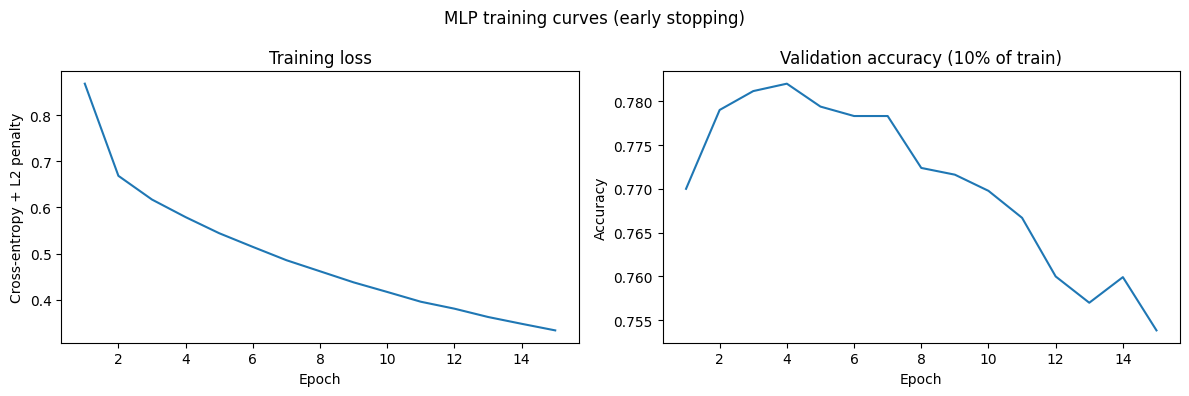

In [12]:
mlp = final_model.named_steps["mlp"]
print(f"Epochs trained: {mlp.n_iter_} (best validation accuracy {mlp.best_validation_score_:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy + L2 penalty")
axes[1].plot(range(1, len(mlp.validation_scores_) + 1), mlp.validation_scores_)
axes[1].set_title("Validation accuracy (10% of train)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
fig.suptitle("MLP training curves (early stopping)")
plt.tight_layout()
plt.show()

## 5. Test Set Evaluation

The held-out test set is used exactly once. Macro-F1 (the unweighted mean of per-product F1) is the
headline metric because it gives small products the same weight as large ones.

In [13]:
test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Test accuracy:    {test_accuracy:.4f}")
print(f"Test macro-F1:    {test_macro_f1:.4f}")
print(f"Test weighted-F1: {test_weighted_f1:.4f}")

Test accuracy:    0.7770
Test macro-F1:    0.7469
Test weighted-F1: 0.7746


In [14]:
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.732     0.775     0.753      4000
                                            Credit card      0.741     0.783     0.762      4000
    Credit reporting or other personal consumer reports      0.822     0.837     0.829      7000
                                        Debt collection      0.749     0.755     0.752      5000
                              Debt or credit management      0.578     0.373     0.453      1000
     Money transfer, virtual currency, or money service      0.773     0.777     0.775      3000
                                               Mortgage      0.891     0.886     0.889      2000
Payday loan, title loan, personal loan, or advance loan      0.641     0.572     0.604      1500
                                           Prepaid card      0.762     0.658     0.706      1000
                             

### Confusion Matrix

Rows are normalized, so each row shows how the complaints of one actual product were distributed across
the predicted products (the diagonal is per-product recall).

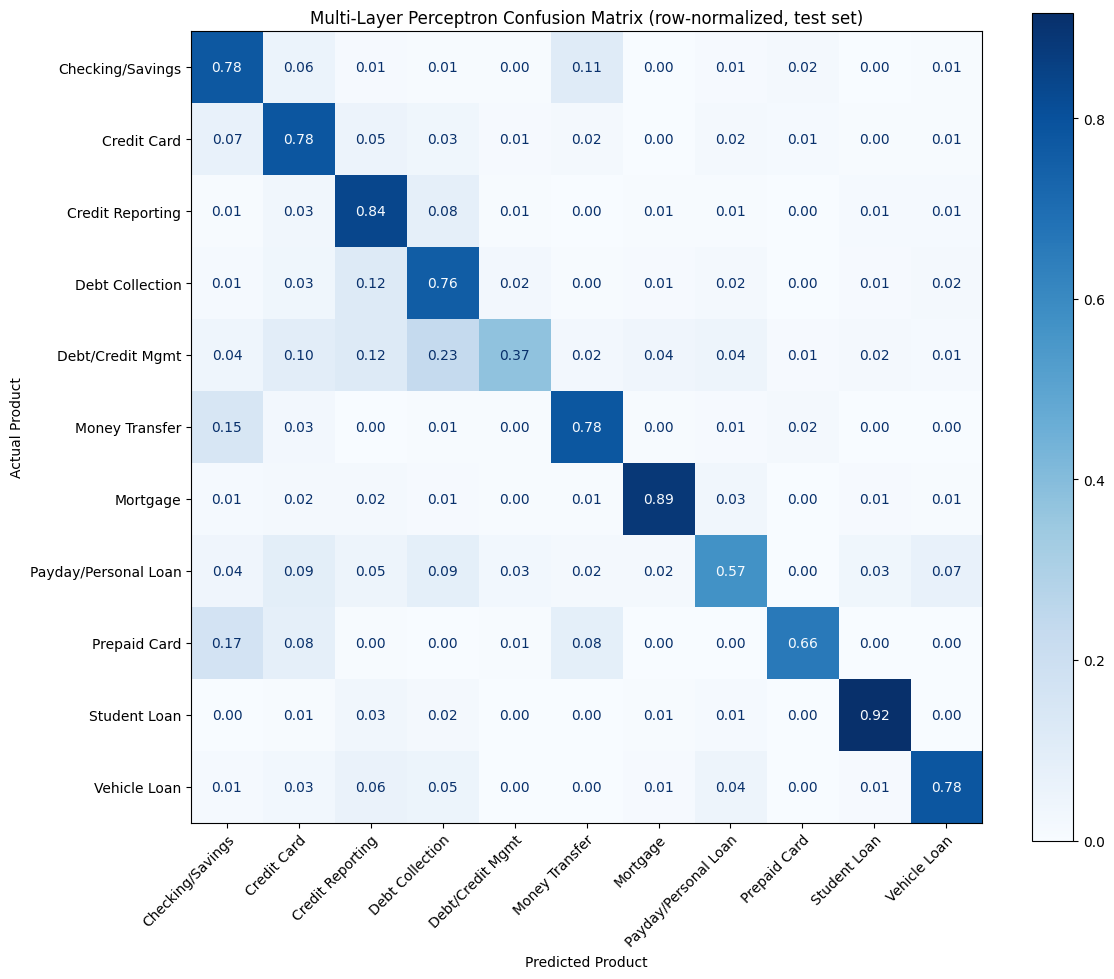

In [15]:
labels = sorted(SHORT_LABELS)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=[SHORT_LABELS[label] for label in labels],
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
ax.set_title(f"{DISPLAY_NAME} Confusion Matrix (row-normalized, test set)")
ax.set_xlabel("Predicted Product")
ax.set_ylabel("Actual Product")
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / f"{MODEL_KEY}_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Save Metrics

Metrics are written to `results/metrics/<model>.json` in the same format as the baseline notebooks so that
`model_comparison.ipynb` can compare all models. Two extra fields are recorded here: `cv_n_samples` (the CV
score comes from the 30k tuning subsample, not the full training set) and `predict_seconds`.

In [16]:
def to_builtin(value):
    # Make parameter values JSON-friendly (tuples -> lists, numpy scalars -> Python)
    if isinstance(value, tuple):
        return [to_builtin(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

metrics = {
    "model": MODEL_KEY,
    "display_name": DISPLAY_NAME,
    "task": "product",
    "features": FEATURES_LABEL,
    "best_params": {name.split("__")[-1]: to_builtin(value) for name, value in best_params.items()},
    "cv_macro_f1": float(search.best_score_),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "per_class": {
        label: {
            "precision": float(report[label]["precision"]),
            "recall": float(report[label]["recall"]),
            "f1": float(report[label]["f1-score"]),
            "support": int(report[label]["support"]),
        }
        for label in labels
    },
    "train_seconds": float(train_seconds),
    "n_train": int(len(y_train)),
    "n_test": int(len(y_test)),
    "cv_n_samples": int(len(y_tune)),
    "predict_seconds": float(predict_seconds),
}

METRICS_DIR.mkdir(parents=True, exist_ok=True)
metrics_path = METRICS_DIR / f"{MODEL_KEY}.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(f"Saved metrics to {metrics_path}")

Saved metrics to ..\..\results\metrics\mlp.json


In [17]:
per_class_f1 = pd.Series(
    {SHORT_LABELS[label]: values["f1"] for label, values in metrics["per_class"].items()}
).sort_values(ascending=False)

print(f"{DISPLAY_NAME} ({FEATURES_LABEL})")
print(f"  Test macro-F1 {test_macro_f1:.3f} | accuracy {test_accuracy:.3f} | weighted-F1 {test_weighted_f1:.3f}")
print(f"  CV macro-F1 (30k subsample) {search.best_score_:.3f} | best params {metrics['best_params']}")
print(f"  Train {train_seconds:.0f}s | predict {predict_seconds:.0f}s | tuning {tune_seconds / 60:.1f} min")
print("\nPer-class F1 (best to worst):")
print(per_class_f1.round(3).to_string())

Multi-Layer Perceptron (TF-IDF → SVD-300)
  Test macro-F1 0.747 | accuracy 0.777 | weighted-F1 0.775
  CV macro-F1 (30k subsample) 0.720 | best params {'alpha': 0.001, 'hidden_layer_sizes': [256]}
  Train 16s | predict 0s | tuning 0.3 min

Per-class F1 (best to worst):
Student Loan            0.895
Mortgage                0.889
Credit Reporting        0.829
Vehicle Loan            0.798
Money Transfer          0.775
Credit Card             0.762
Checking/Savings        0.753
Debt Collection         0.752
Prepaid Card            0.706
Payday/Personal Loan    0.604
Debt/Credit Mgmt        0.453


## MLP Results Summary

- **Best hyperparameters** (3-fold CV on the 30k subsample): one hidden layer of 256 units with `alpha=1e-3`, CV macro-F1 **0.720**. The two alpha values are nearly tied (0.7198 vs 0.7195). The deeper (512, 128) network was about 0.01 worse and took twice as long, which suggests the extra capacity mostly overfits 20k-sample folds.
- **Test set:** macro-F1 **0.747**, accuracy **77.7%**, weighted-F1 **0.775**.
- **Strongest products:** Student Loan (F1 0.895), Mortgage (0.889) and Credit Reporting (0.829).
- **Weakest products:** Debt/Credit Management (0.453; recall 0.37, with 23% predicted as Debt Collection), Payday/Personal Loan (0.604) and Prepaid Card (0.706; 17% predicted as Checking/Savings). Without class weighting these small products still have the lowest recall, but less so than with k-NN.
- **Training:** early stopping ended training after **15 epochs**. Validation accuracy (best 0.782) peaked around epoch 5 and the best weights were restored, so the network fits the LSA features quickly. The final fit on 130k complaints took **15.8 s**; prediction took 0.1 s.
- **Compared with the other models:** the MLP is the best of the SVD-300 models run so far (k-NN macro-F1 0.709). It beats Naive Bayes / Complement NB (0.723 / 0.721) but is still behind Logistic Regression on the full 100k TF-IDF (0.776). This suggests compressing to 300 LSA dimensions costs more than a non-linear model gains back. See `model_comparison.ipynb` for the full table.